In [2]:
import warnings
from pathlib import Path

import zarr

warnings.filterwarnings("ignore")

print("Your zarr version: ", zarr.__version__, " -- Tutorial is tested with 3.0.7")


# mission = "2024-11-02-17-18-32"
# mission = "2024-10-01-11-29-55"

mission = "2024-10-01-11-29-55"

# Should be path to the dataset folder that holds all missions

# grand_tour_folder = Path("~/grand_tour_dataset").expanduser()
grand_tour_folder = Path("/datahome/lmertens/grand_tour_dataset")

# Specifc mission with ./data and ./images folder
mission_folder = grand_tour_folder / mission

mission_root = zarr.open_group(store=mission_folder / "data", mode="r")

# List group members
print("Zarr root keys:", list(mission_root.keys()))
mission_root


odometry_topic = "cpt7_ie_tc_odometry"
command_topic = "anymal_command_twist"
prism_topic = "prism_position"

Your zarr version:  3.1.6  -- Tutorial is tested with 3.0.7
Zarr root keys: ['zed2i_right_images', 'adis_imu', 'zed2i_depth_image', 'zed2i_vio_map', 'anymal_state_battery', 'ap20_imu', 'dlio_tf', 'gnss_raw_cpt7_ie_tc', 'stim320_accelerometer_temperature', 'gnss_raw_cpt7_ie_rt', 'tf', 'stim320_gyroscope_temperature', 'prism_position', 'cpt7_ie_tc_tf', 'cpt7_ie_rt_tf', 'anymal_state_odometry', 'zed2i_left_images', 'anymal_state_state_estimator', 'stim320_imu', 'anymal_imu', 'anymal_state_actuator', 'navsatfix_cpt7_ie_tc', 'cpt7_imu', 'dlio_map_odometry', 'cpt7_ie_rt_odometry', 'anymal_command_twist', 'cpt7_ie_tc_odometry']


In [2]:
# @title Plot Trajectory
import numpy as np
import plotly.graph_objects as go

# Ground-truth trajectory from GNSS/INS topic
ground_truth_topic = "prism_position"
ground_truth_numpy = np.asarray(mission_root[ground_truth_topic]["point"])
ground_truth_frame = mission_root[ground_truth_topic].attrs["frame_id"]

odometry_topic = "cpt7_ie_tc_odometry"
odometry_numpy = np.asarray(mission_root[odometry_topic]["pose_pos"])
odometry_frame = mission_root[odometry_topic].attrs["frame_id"]


ground_truth_numpy = (
    ground_truth_numpy - ground_truth_numpy[0]
)  # Normalize to start at origin


# Extract X, Y, Z coordinates
x, y, z = ground_truth_numpy[:, 0], ground_truth_numpy[:, 1], ground_truth_numpy[:, 2]

# Create a 3D scatter plot with a trajectory line
fig = go.Figure()

# Add trajectory line
fig.add_trace(
    go.Scatter3d(
        x=x, y=y, z=z, mode="lines", line=dict(color="blue", width=3), name="Trajectory"
    )
)

# Add start & end points
fig.add_trace(
    go.Scatter3d(
        x=[x[0]],
        y=[y[0]],
        z=[z[0]],
        mode="markers",
        marker=dict(size=8, color="green"),
        name="Start",
    )
)

fig.add_trace(
    go.Scatter3d(
        x=[x[-1]],
        y=[y[-1]],
        z=[z[-1]],
        mode="markers",
        marker=dict(size=8, color="red"),
        name="End",
    )
)

fig.add_trace(
    go.Scatter3d(
        x=odometry_numpy[:, 0],
        y=odometry_numpy[:, 1],
        z=odometry_numpy[:, 2],
        mode="lines",
        line=dict(color="orange", width=3),
        name="Odometry",
    )
)

# Start & end points for odometry
fig.add_trace(
    go.Scatter3d(
        x=[odometry_numpy[0, 0]],
        y=[odometry_numpy[0, 1]],
        z=[odometry_numpy[0, 2]],
        mode="markers",
        marker=dict(size=8, color="cyan"),
        name="Odometry Start",
    )
)

# Compute axis limits to ensure equal scale
max_range = (
    np.array([x.max() - x.min(), y.max() - y.min(), z.max() - z.min()]).max() / 2.0
)
mid_x = (x.max() + x.min()) / 2.0
mid_y = (y.max() + y.min()) / 2.0
mid_z = (z.max() + z.min()) / 2.0

# Update layout with equal axis scaling
fig.update_layout(
    title="3D ANYmal D Trajectory (Z Axis Scale Enlarged)",
    # scene=dict(
    #     xaxis=dict(range=[mid_x - max_range, mid_x + max_range]),
    #     yaxis=dict(range=[mid_y - max_range, mid_y + max_range]),
    #     zaxis=dict(range=[mid_z - max_range / 10, mid_z + max_range / 10]),
    # ),
    # margin=dict(l=0, r=0, b=0, t=40),
)

fig.show()

[1.72777501e+09 1.72777501e+09 1.72777501e+09 1.72777501e+09
 1.72777501e+09]


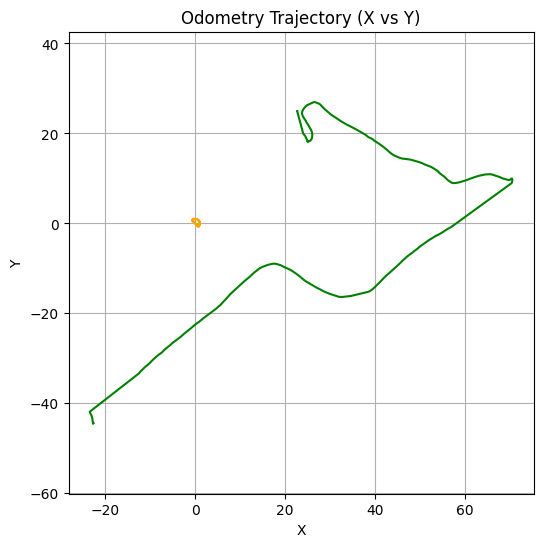

In [3]:
import matplotlib.pyplot as plt
import numpy as np

odometry_topic = "cpt7_ie_tc_odometry"

odometry_timestamps = np.asarray(mission_root[odometry_topic]["timestamp"])
odometry_numpy = np.asarray(mission_root[odometry_topic]["pose_orien"])
odometry_frame = mission_root[odometry_topic].attrs["frame_id"]


print(odometry_timestamps[:5])  # Print first 5 timestamps to check the data


topic = "prism_position"
subtopic = "point"

prism_timestamps = np.asarray(mission_root[topic]["timestamp"])
prism_numpy = np.asarray(mission_root[topic][subtopic])


# lookup = FastTfLookup(mission_root=mission_root, odom_key=odometry_topic)


# cpt7_transform_topic = "cpt7_ie_tc_tf"
# cpt7_transform_numpy = np.asarray(mission_root[cpt7_transform_topic]["translation"])

# odometry_numpy = (
#     odometry_numpy + cpt7_transform_numpy
# )  # Apply the transform to the odometry trajectory


shared_timestamps = odometry_timestamps[
    (odometry_timestamps >= prism_timestamps[0])
    & (odometry_timestamps <= prism_timestamps[-1])
]
prism_shared = np.column_stack([
    np.interp(shared_timestamps, prism_timestamps, prism_numpy[:, axis])
    for axis in range(prism_numpy.shape[1])
])
odometry_shared = odometry_numpy[
    (odometry_timestamps >= prism_timestamps[0])
    & (odometry_timestamps <= prism_timestamps[-1])
]


# Plot x and y against each other to see the trajectory in 2D
plt.figure(figsize=(6, 6))
plt.plot(odometry_shared[:, 0], odometry_shared[:, 1], color="orange")
plt.plot(prism_shared[:, 0], prism_shared[:, 1], color="green")
plt.title("Odometry Trajectory (X vs Y)")
plt.xlabel("X")
plt.ylabel("Y")
plt.axis("equal")
plt.grid()
plt.show()

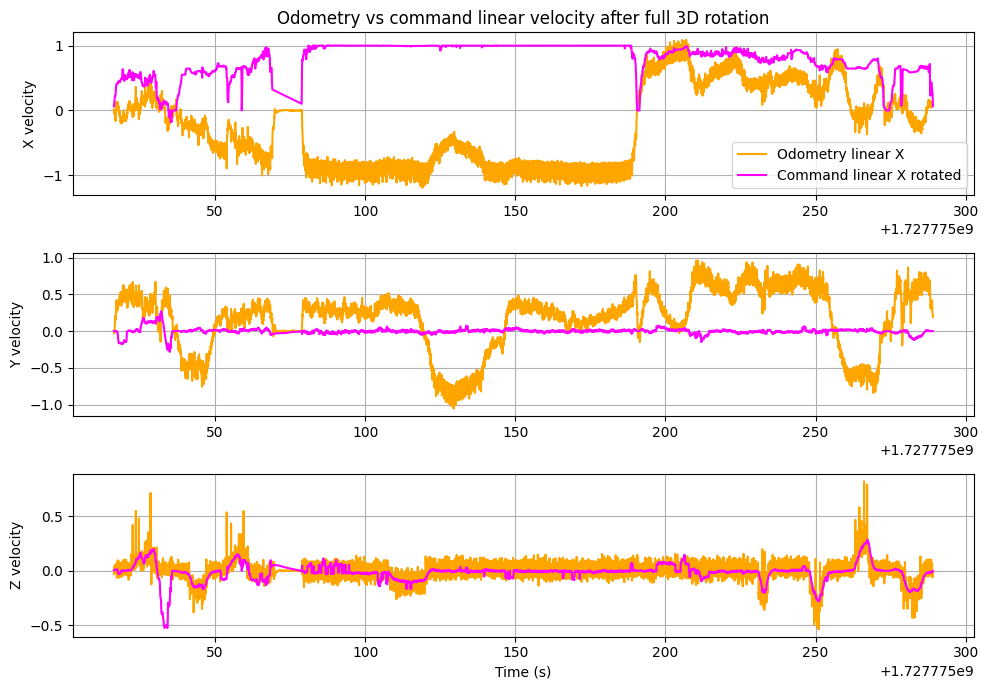

In [5]:
# There are two twists:
# - anymal-command-twist (in the body frame)
# - cpt7_ie_tc_odometry (in ENU-origin / world frame)
# To-verify: Can we roughly align the anymal-command-twist with the cpt7_ie_tc_odometry by applying the current orientation of the robot to the linear velocity command?

import matplotlib.pyplot as plt
import numpy as np
from data_labeling_pipeline.dataset_loader import get_shared_timestamps

odometry = mission_root[odometry_topic]
command = mission_root[command_topic]

odometry_ts = np.asarray(odometry["timestamp"])
odometry_linear = np.asarray(odometry["twist_lin"])
odometry_orientation = np.asarray(odometry["pose_orien"])  # Quaternions in wxyz

command_ts = np.asarray(command["timestamp"])
command_linear = np.asarray(command["linear"])
command_angular = np.asarray(command["angular"])

shared_ts = get_shared_timestamps(odometry_ts, command_ts, dt=0.01)
if shared_ts.size < 2:
    raise ValueError("No overlapping timestamps between odometry and command topics.")


def interpolate_columns(
    timestamps: np.ndarray, values: np.ndarray, query_timestamps: np.ndarray
) -> np.ndarray:
    return np.column_stack([
        np.interp(query_timestamps, timestamps, values[:, axis])
        for axis in range(values.shape[1])
    ])


def rotate_vectors_by_quaternion(
    vectors: np.ndarray, quaternions_wxyz: np.ndarray
) -> np.ndarray:
    quaternion_norm = np.linalg.norm(quaternions_wxyz, axis=1, keepdims=True)
    quaternions_wxyz = quaternions_wxyz / np.where(
        quaternion_norm == 0.0, 1.0, quaternion_norm
    )

    q_w = quaternions_wxyz[:, 0:1]
    q_xyz = quaternions_wxyz[:, 1:4]

    t = 2.0 * np.cross(q_xyz, vectors)
    return vectors + q_w * t + np.cross(q_xyz, t)


odometry_linear_shared_3d = interpolate_columns(odometry_ts, odometry_linear, shared_ts)
odometry_orientation_shared = interpolate_columns(
    odometry_ts, odometry_orientation, shared_ts
)
command_linear_shared = interpolate_columns(command_ts, command_linear, shared_ts)
command_angular_shared = interpolate_columns(command_ts, command_angular, shared_ts)

command_linear_rotated_3d = rotate_vectors_by_quaternion(
    command_linear_shared, odometry_orientation_shared
)

# Keep the scalar variables used by the later diagnostic plots.
odometry_linear_shared = odometry_linear_shared_3d[:, 0]
command_linear_rotated = command_linear_rotated_3d[:, 0]

# Useful if you want to inspect the full 3D alignment later.
odometry_linear_shared_xy = odometry_linear_shared_3d[:, :2]
command_linear_rotated_xy = command_linear_rotated_3d[:, :2]

plt.figure(figsize=(10, 7))
component_labels = ["X", "Y", "Z"]
for axis, label in enumerate(component_labels, start=1):
    plt.subplot(3, 1, axis)
    plt.plot(
        shared_ts,
        odometry_linear_shared_3d[:, axis - 1],
        label=f"Odometry linear {label}",
        color="orange",
    )
    plt.plot(
        shared_ts,
        command_linear_rotated_3d[:, axis - 1],
        label=f"Command linear {label} rotated",
        color="magenta",
    )
    plt.ylabel(f"{label} velocity")
    plt.grid(True)
    if axis == 1:
        plt.title("Odometry vs command linear velocity after full 3D rotation")
    if axis == 3:
        plt.xlabel("Time (s)")
    if axis == 1:
        plt.legend(loc="lower right")

plt.tight_layout()
plt.show()

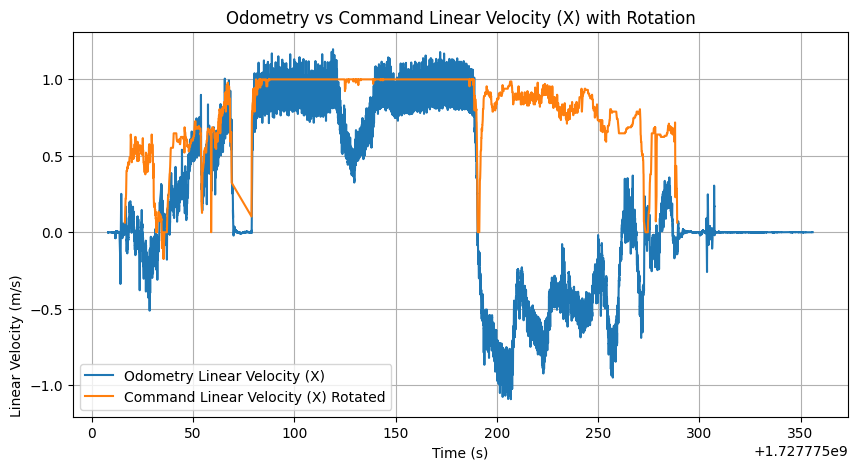

In [6]:
plt.figure(figsize=(10, 5))
plt.plot(
    np.asarray(odometry_ts),
    -np.asarray(odometry_linear)[:, 0],
    label="Odometry Linear Velocity (X)",
)
plt.plot(
    np.asarray(command_ts),
    np.asarray(command_linear)[:, 0],
    label="Command Linear Velocity (X) Rotated",
)
plt.title("Odometry vs Command Linear Velocity (X) with Rotation")
plt.xlabel("Time (s)")
plt.ylabel("Linear Velocity (m/s)", loc="bottom")
plt.legend()
plt.grid()
plt.show()

Correlation with odometry by axis (x, y, z):
  raw: [-0.378  0.038    nan]
  rotated_by_q: [-0.38  -0.126  0.577]
  rotated_by_q_inv: [-0.379  0.054 -0.132]


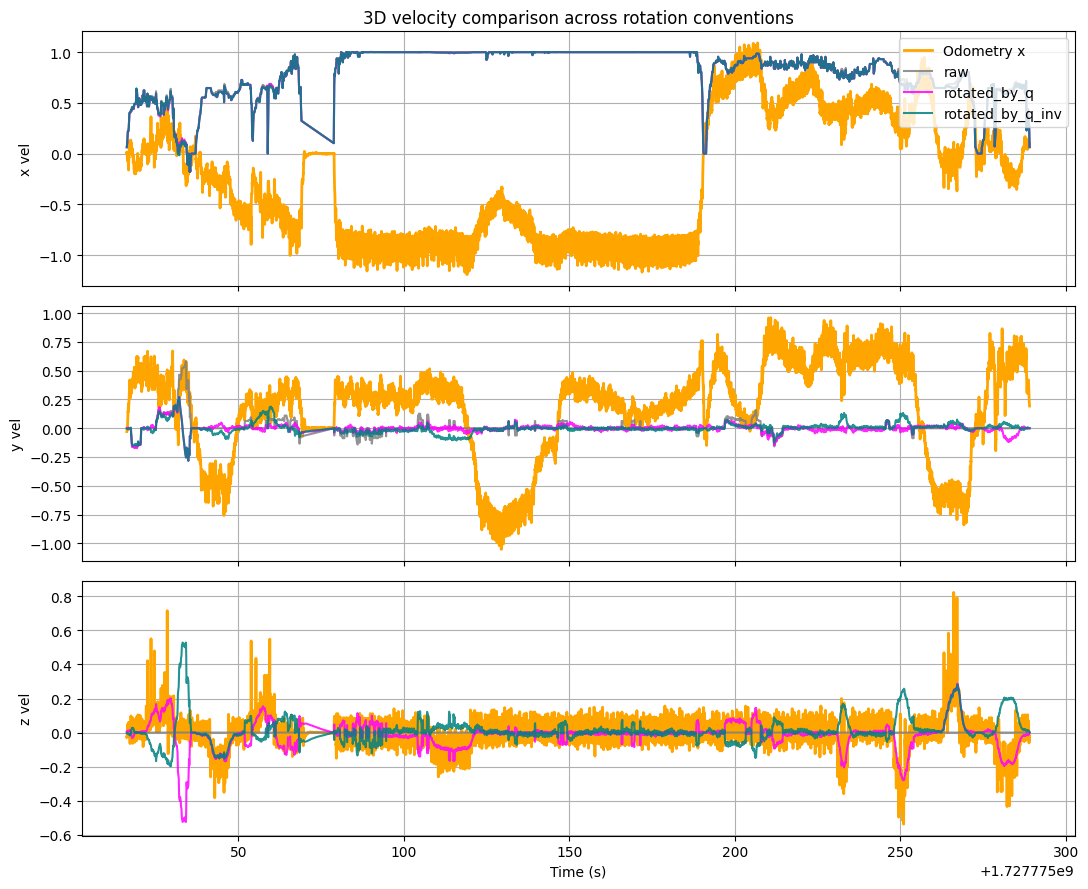

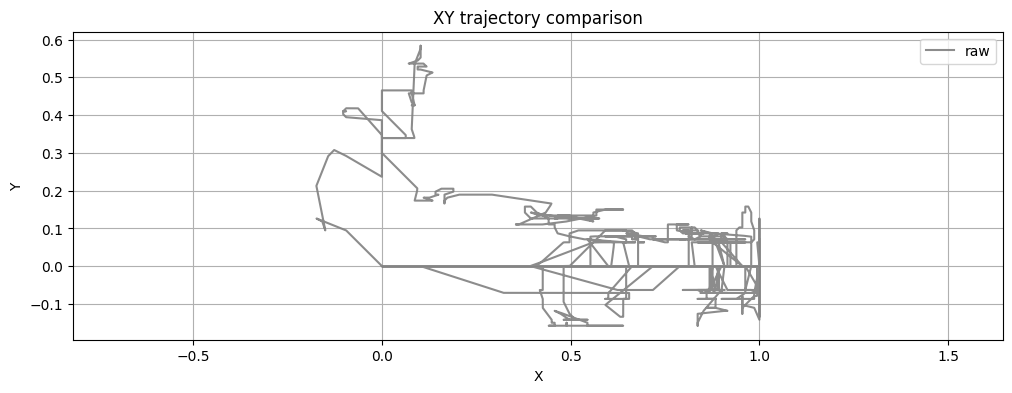

In [7]:
# Diagnostic comparison: unrotated command vs rotation by q vs rotation by q^{-1}
# If one of the rotated variants matches better, the issue is likely a frame convention mismatch.

import matplotlib.pyplot as plt
import numpy as np


def quaternion_conjugate_wxyz(quaternions_wxyz: np.ndarray) -> np.ndarray:
    conjugated = quaternions_wxyz.copy()
    conjugated[:, 1:4] *= -1.0
    return conjugated


command_linear_unrotated_3d = command_linear_shared
command_linear_rotated_inv_3d = rotate_vectors_by_quaternion(
    command_linear_shared,
    quaternion_conjugate_wxyz(odometry_orientation_shared),
)

# Use the full 3D vectors for comparison.
odom = odometry_linear_shared_3d
cmd_raw = command_linear_unrotated_3d
cmd_rot = command_linear_rotated_3d
cmd_inv = command_linear_rotated_inv_3d

variants = {
    "raw": cmd_raw,
    "rotated_by_q": cmd_rot,
    "rotated_by_q_inv": cmd_inv,
}

print("Correlation with odometry by axis (x, y, z):")
for name, values in variants.items():
    correlations = [
        np.corrcoef(odom[:, axis], values[:, axis])[0, 1] for axis in range(3)
    ]
    print(f"  {name}: {np.round(correlations, 3)}")

fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
axis_labels = ["x", "y", "z"]
colors = {"raw": "gray", "rotated_by_q": "magenta", "rotated_by_q_inv": "teal"}

for axis_index, axis_name in enumerate(axis_labels):
    axes[axis_index].plot(
        shared_ts,
        odom[:, axis_index],
        label=f"Odometry {axis_name}",
        color="orange",
        linewidth=2,
    )
    for variant_name, values in variants.items():
        axes[axis_index].plot(
            shared_ts,
            values[:, axis_index],
            label=variant_name,
            color=colors[variant_name],
            alpha=0.85,
        )
    axes[axis_index].set_ylabel(f"{axis_name} vel")
    axes[axis_index].grid(True)
    if axis_index == 0:
        axes[axis_index].set_title("3D velocity comparison across rotation conventions")
        axes[axis_index].legend(loc="upper right")

axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
for label, values, color in [
    ("raw", cmd_raw, "gray"),
    # ("rotated_by_q", cmd_rot, "magenta"),
    # ("rotated_by_q_inv", cmd_inv, "teal"),
]:
    plt.plot(values[:, 0], values[:, 1], label=label, color=color, alpha=0.9)
# plt.plot(odom[:, 0], odom[:, 1], label="odometry", color="orange", linewidth=2)
plt.title("XY trajectory comparison")
plt.xlabel("X")
plt.ylabel("Y")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

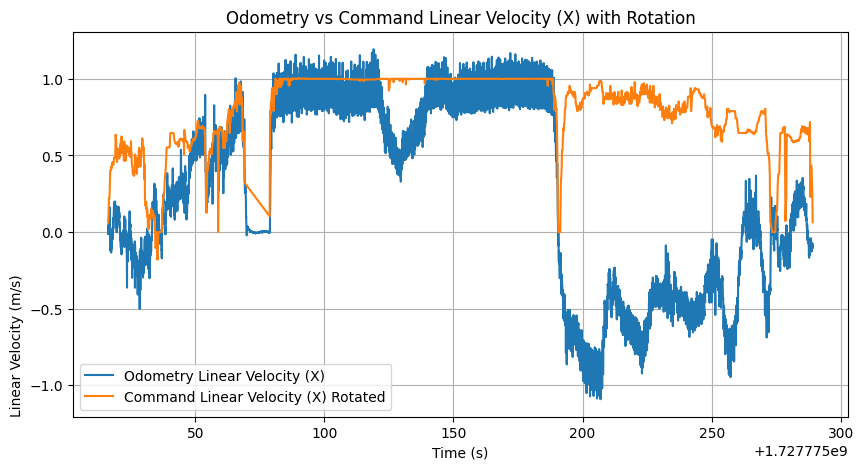

In [8]:
# Plot theta first

# command_angular = command["angular"]
# command_theta_shared = np.interp(shared_ts, command_ts, command_angular[:, 2])


plt.figure(figsize=(10, 5))
plt.plot(shared_ts, -odometry_linear_shared, label="Odometry Linear Velocity (X)")
plt.plot(shared_ts, command_linear_rotated, label="Command Linear Velocity (X) Rotated")
plt.title("Odometry vs Command Linear Velocity (X) with Rotation")
plt.xlabel("Time (s)")
plt.ylabel("Linear Velocity (m/s)", loc="bottom")
plt.legend()
plt.grid()
plt.show()

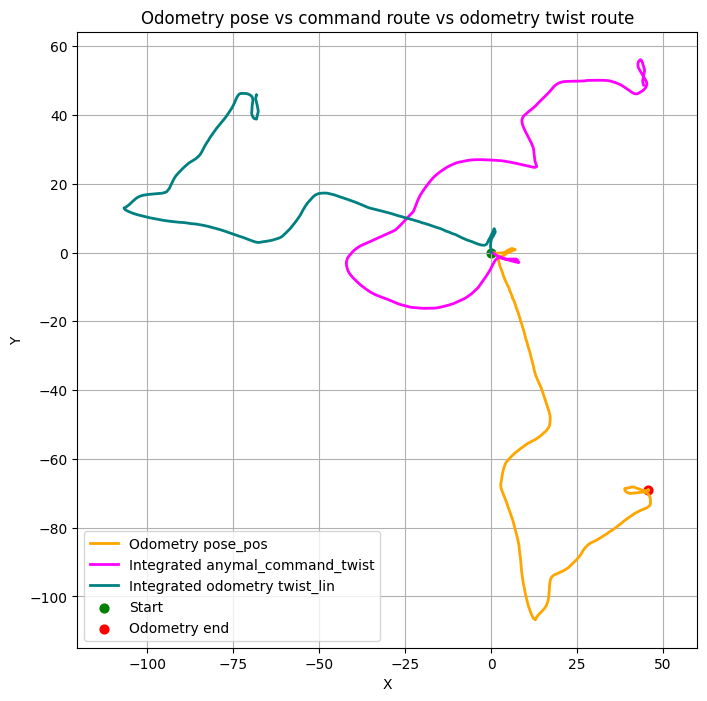

Filled command gaps with zero commands: 252 inserted samples
Command route final error: 117.834 m
Odometry twist route final error: 161.841 m


In [9]:
# Compare odometry pose with:
# 1) route implied by anymal_command_twist (with zero-filled command gaps)
# 2) route implied by odometry twist_lin

import matplotlib.pyplot as plt
import numpy as np
from data_labeling_pipeline.dataset_loader import get_shared_timestamps


def interpolate_columns(
    timestamps: np.ndarray, values: np.ndarray, query_timestamps: np.ndarray
) -> np.ndarray:
    return np.column_stack([
        np.interp(query_timestamps, timestamps, values[:, axis])
        for axis in range(values.shape[1])
    ])


def quaternion_to_yaw_wxyz(quaternion_wxyz: np.ndarray) -> float:
    w, x, y, z = quaternion_wxyz
    return np.arctan2(2.0 * (w * z + x * y), 1.0 - 2.0 * (y * y + z * z))


def fill_command_gaps_with_zero_commands(
    timestamps: np.ndarray,
    linear: np.ndarray,
    angular: np.ndarray,
    gap_factor: float = 3.0,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    if timestamps.size < 2:
        return timestamps, linear, angular

    diffs = np.diff(timestamps)
    positive_diffs = diffs[diffs > 0]
    if positive_diffs.size == 0:
        return timestamps, linear, angular

    nominal_dt = float(np.median(positive_diffs))
    if nominal_dt <= 0.0 or not np.any(diffs > gap_factor * nominal_dt):
        return timestamps, linear, angular

    filled_ts = [timestamps[0]]
    filled_lin = [linear[0]]
    filled_ang = [angular[0]]
    zero_lin = np.zeros(linear.shape[1], dtype=linear.dtype)
    zero_ang = np.zeros(angular.shape[1], dtype=angular.dtype)

    for index in range(timestamps.size - 1):
        t0 = timestamps[index]
        t1 = timestamps[index + 1]
        if diffs[index] > gap_factor * nominal_dt:
            for missing_t in np.arange(
                t0 + nominal_dt, t1, nominal_dt, dtype=timestamps.dtype
            ):
                filled_ts.append(missing_t)
                filled_lin.append(zero_lin.copy())
                filled_ang.append(zero_ang.copy())

        filled_ts.append(t1)
        filled_lin.append(linear[index + 1])
        filled_ang.append(angular[index + 1])

    return (
        np.asarray(filled_ts, dtype=timestamps.dtype),
        np.asarray(filled_lin, dtype=linear.dtype),
        np.asarray(filled_ang, dtype=angular.dtype),
    )


def integrate_route_from_body_twist(
    timestamps: np.ndarray,
    linear_body_xy: np.ndarray,
    initial_xy: np.ndarray,
    initial_heading: float,
    heading_mode: str,
    heading_signal: np.ndarray,
) -> np.ndarray:
    route = np.empty((timestamps.size, 2), dtype=float)
    route[0] = initial_xy
    heading = initial_heading

    for index in range(1, timestamps.size):
        dt = timestamps[index] - timestamps[index - 1]
        vx_body, vy_body = linear_body_xy[index - 1]

        cos_heading = np.cos(heading)
        sin_heading = np.sin(heading)
        vx_world = cos_heading * vx_body - sin_heading * vy_body
        vy_world = sin_heading * vx_body + cos_heading * vy_body

        route[index, 0] = route[index - 1, 0] + vx_world * dt
        route[index, 1] = route[index - 1, 1] + vy_world * dt

        if heading_mode == "integrate_omega_z":
            heading += heading_signal[index - 1]
        elif heading_mode == "follow_heading":
            heading = heading_signal[index]
        else:
            raise ValueError(f"Unsupported heading_mode: {heading_mode}")

    return route


odometry = mission_root[odometry_topic]
command = mission_root[command_topic]

odometry_ts = np.asarray(odometry["timestamp"])
odometry_pose_pos = np.asarray(odometry["pose_pos"])
odometry_pose_orien = np.asarray(odometry["pose_orien"])
odometry_twist_lin = np.asarray(odometry["twist_lin"])

command_ts = np.asarray(command["timestamp"])
command_linear = np.asarray(command["linear"])
command_angular = np.asarray(command["angular"])

shared_ts = get_shared_timestamps(odometry_ts, command_ts, dt=0.01)
if shared_ts.size < 2:
    raise ValueError("No overlapping timestamps between odometry and command topics.")

command_ts_filled, command_linear_filled, command_angular_filled = (
    fill_command_gaps_with_zero_commands(command_ts, command_linear, command_angular)
)

odometry_pos_shared = interpolate_columns(odometry_ts, odometry_pose_pos, shared_ts)
odometry_orien_shared = interpolate_columns(odometry_ts, odometry_pose_orien, shared_ts)
command_linear_shared = interpolate_columns(
    command_ts_filled, command_linear_filled, shared_ts
)
command_angular_shared = interpolate_columns(
    command_ts_filled, command_angular_filled, shared_ts
)

odometry_yaw_full = np.array([quaternion_to_yaw_wxyz(q) for q in odometry_pose_orien])
odometry_yaw_shared = np.array([
    quaternion_to_yaw_wxyz(q) for q in odometry_orien_shared
])


# Note: keep this as angular velocity * dt at each step for integration mode.
command_heading_step = command_angular_shared[:, 2] * np.diff(
    shared_ts, append=shared_ts[-1]
)
command_route = integrate_route_from_body_twist(
    timestamps=shared_ts,
    linear_body_xy=command_linear_shared[:, :2],
    initial_xy=odometry_pos_shared[0, :2],
    # initial_heading=odometry_yaw_shared[0],
    initial_heading=0,
    heading_mode="integrate_omega_z",
    heading_signal=command_heading_step,
)

odometry_twist_lin_full = interpolate_columns(
    odometry_ts, odometry_twist_lin, odometry_ts
)
odometry_twist_route = integrate_route_from_body_twist(
    timestamps=odometry_ts,
    linear_body_xy=odometry_twist_lin_full[:, :2],
    initial_xy=odometry_pose_pos[0, :2],
    # initial_heading=odometry_yaw_full[0],
    initial_heading=0,
    heading_mode="follow_heading",
    heading_signal=odometry_yaw_full,
)

plt.figure(figsize=(8, 8))
plt.plot(
    odometry_pose_pos[:, 0],
    odometry_pose_pos[:, 1],
    label="Odometry pose_pos",
    color="orange",
    linewidth=2,
)
plt.plot(
    command_route[:, 0],
    command_route[:, 1],
    label="Integrated anymal_command_twist",
    color="magenta",
    linewidth=2,
)
plt.plot(
    odometry_twist_route[:, 0],
    odometry_twist_route[:, 1],
    label="Integrated odometry twist_lin",
    color="teal",
    linewidth=2,
)
plt.scatter(
    [odometry_pose_pos[0, 0]],
    [odometry_pose_pos[0, 1]],
    color="green",
    s=40,
    label="Start",
)
plt.scatter(
    [odometry_pose_pos[-1, 0]],
    [odometry_pose_pos[-1, 1]],
    color="red",
    s=40,
    label="Odometry end",
)
plt.title("Odometry pose vs command route vs odometry twist route")
plt.xlabel("X")
plt.ylabel("Y")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

odometry_pos_on_shared = interpolate_columns(odometry_ts, odometry_pose_pos, shared_ts)
command_error = np.linalg.norm(command_route - odometry_pos_on_shared[:, :2], axis=1)
odometry_twist_error = np.linalg.norm(
    odometry_twist_route - odometry_pose_pos[:, :2], axis=1
)

print(
    f"Filled command gaps with zero commands: {command_ts_filled.size - command_ts.size} inserted samples"
)
print(f"Command route final error: {command_error[-1]:.3f} m")
print(f"Odometry twist route final error: {odometry_twist_error[-1]:.3f} m")

Median dt: 0.050s, regular diffs: 5160/5190
-0.4819305290591096


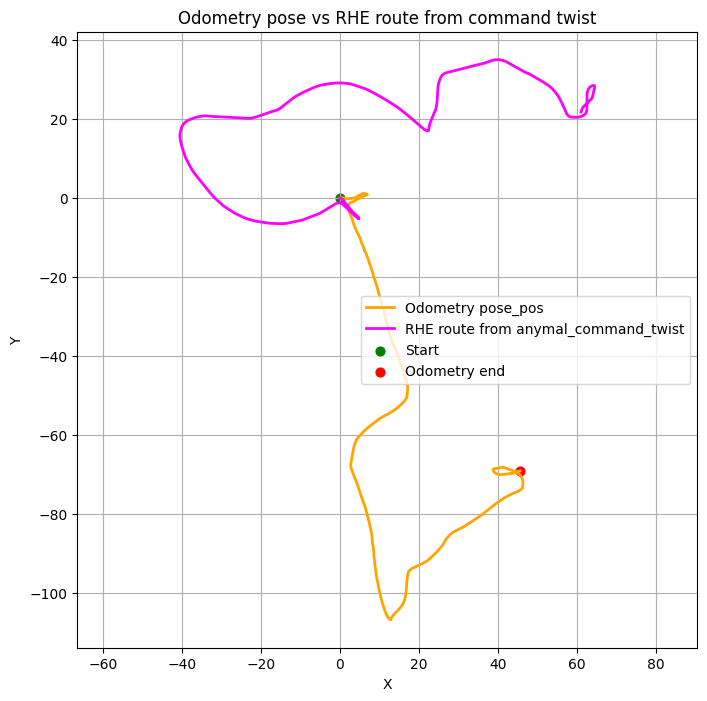

Filled command gaps with zero commands: 237 inserted samples
Final position error: 92.180 m
Mean position error: 76.432 m


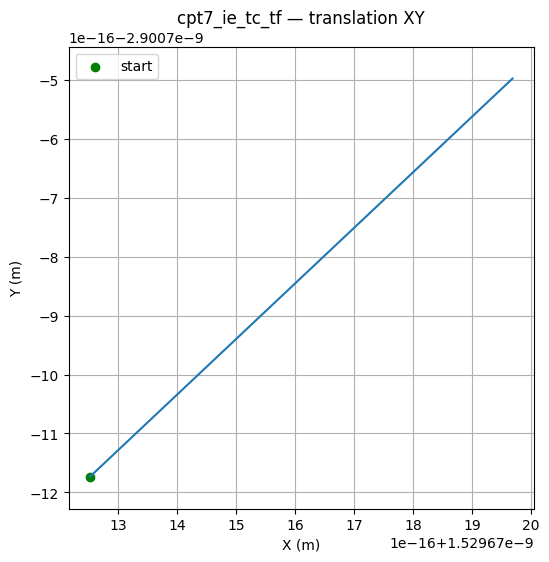

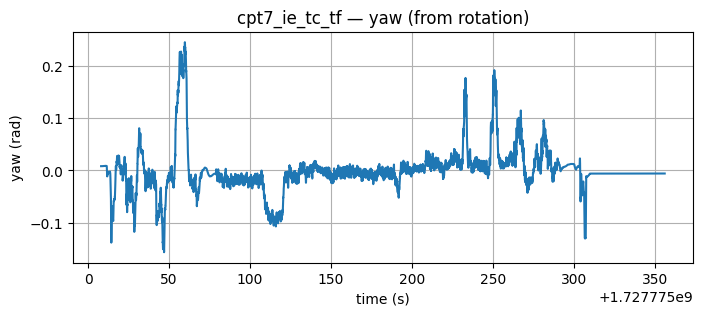

In [24]:
# Plot cpt7_ie_tc_tf — translation XY + yaw over time
import matplotlib.pyplot as plt
import numpy as np

topic = "cpt7_ie_tc_tf"
tf = mission_root[topic]

# Try to read arrays (robust if single sample)
ts = np.asarray(tf["timestamp"])
trans = np.asarray(tf["translation"])
rot = np.asarray(tf["rotation"])  # expect wxyz

# If transform static (single sample), still plot point
if trans.ndim == 1:
    trans = trans.reshape(1, -1)
if rot.ndim == 1:
    rot = rot.reshape(1, -1)

# Translation XY
plt.figure(figsize=(6, 6))
plt.plot(trans[:2, 0], trans[:2, 1])
plt.scatter(trans[0, 0], trans[0, 1], color="green", label="start")
# plt.scatter(trans[-1, 0], trans[-1, 1], color="red", label="end")
plt.title(f"{topic} — translation XY")
plt.xlabel("X (m)")
plt.ylabel("Y (m)")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()


# Quaternion -> yaw (w,x,y,z) to yaw (rad)
def quat_to_yaw_wxyz(q):
    w, x, y, z = q
    return np.arctan2(2.0 * (w * z + x * y), 1.0 - 2.0 * (y * y + z * z))


yaws = np.array([quat_to_yaw_wxyz(q) for q in rot])

plt.figure(figsize=(8, 3))
plt.plot(ts, yaws, "-")
plt.title(f"{topic} — yaw (from rotation)")
plt.xlabel("time (s)")
plt.ylabel("yaw (rad)")
plt.grid(True)
plt.show()

Using scalar_first = True for quaternion to yaw conversion.


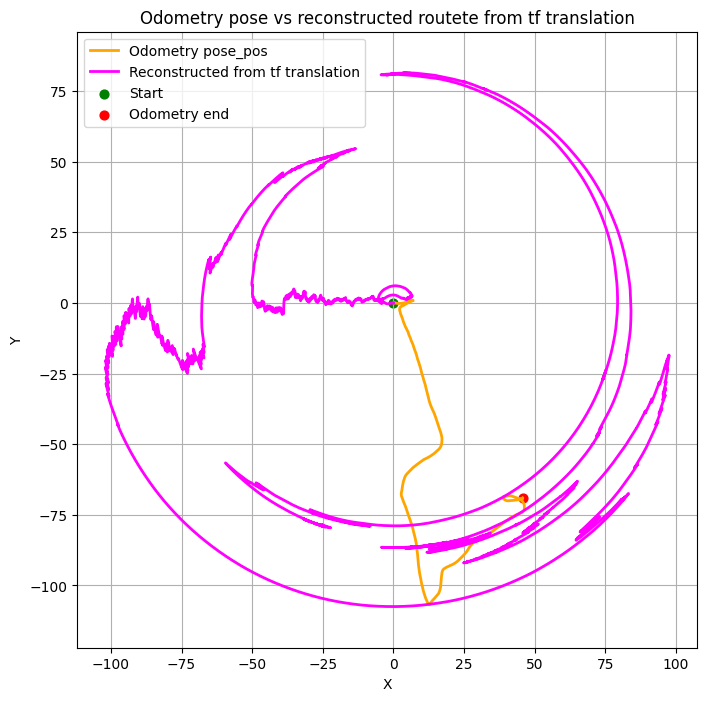

In [ ]:
import numpy as np
from data_labeling_pipeline.dataset_loader import quaternions_to_yaws

tf = mission_root["cpt7_ie_tc_tf"]  # in cpt7_imu frame
odom = mission_root["cpt7_ie_tc_odometry"]  # in ENU-origin frame

t = np.asarray(tf["translation"])[:, :2]
q = np.asarray(odom["pose_orien"])  # wxyz
p = np.asarray(odom["pose_pos"])[:, :2]


yaw = quaternions_to_yaws(q, scalar_first=False)

# rotate body-frame translation into world frame
c, s = np.cos(yaw), np.sin(yaw)
t_world = np.column_stack([c * t[:, 0] - s * t[:, 1], s * t[:, 0] + c * t[:, 1]])

# Compare directly — do NOT add p
recon = t_world


# Plot the reconstructed trajectory vs the original odometry pose
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))
plt.plot(p[:, 0], p[:, 1], label="Odometry pose_pos", color="orange", linewidth=2)
plt.plot(
    recon[:, 0],
    recon[:, 1],
    label="Reconstructed from tf translation",
    color="magenta",
    linewidth=2,
)
plt.scatter(p[0, 0], p[0, 1], color="green", s=40, label="Start")
plt.scatter(p[-1, 0], p[-1, 1], color="red", s=40, label="Odometry end")
plt.title("Odometry pose vs reconstructed routete from tf translation")
plt.xlabel("X")
plt.ylabel("Y")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()


In [27]:
# If you have the raw SE3 from the topic:

from data_labeling_pipeline.zarr_transforms import inv
from scipy.spatial.transform import Rotation as R


def pq_to_se3(ps, qs):
    """Convert position + quaternion into a 4x4 SE(3) matrix."""
    pos = np.asarray(ps, dtype=np.float64)
    quat = np.asarray(qs, dtype=np.float64)

    se3s = np.zeros((pos.shape[0], 4, 4), dtype=np.float64)

    se3s[:, :3, :3] = R.from_quat(quat).as_matrix()
    se3s[:, :3, 3] = pos
    return se3s


tf = mission_root["cpt7_ie_tc_tf"]
translation = np.asarray(tf["translation"])  # single sample expected
rotation = np.asarray(tf["rotation"])  # single sample expected


T = pq_to_se3(translation, rotation)

# The translation of T_odom_to_imu IS the position in world frame:
# position_world = T[:3, 3]  # ← use this if T is already odom→imu

# If T is actually imu→odom (inverse), fix it:
T_odom_to_imu = inv(T)
position_world = T_odom_to_imu[:3, 3]

plt.figure()
plt.plot(position_world[0], position_world[1], label="Position from SE3")

ValueError: could not broadcast input array from shape (4,3,3) into shape (3,3)

In [ ]:
lookup = FastTfLookup(
    odom_key="cpt7_ie_tc_odometry",  # your dynamic topic
    mission_root=mission_root,
    parent="odom",  # whatever the parent frame is
    child="cpt7_imu",  # the IMU frame
)

translation = mission_root["cpt7_ie_tc_tf"]["translation"]


world_positions = []

for timestamp in mission_root["cpt7_ie_tc_tf"]["timestamp"][::10]:
    T = lookup(timestamp)
    # Apply the transform to the translation.
    r = T @ np.hstack([translation, 1.0])  # homogenous coordinates

    world_positions.append(r[:3])

# Plot the trajectory in 2d
world_positions = np.array(world_positions)
plt.figure(figsize=(8, 8))
plt.plot(
    world_positions[:, 0], world_positions[:, 1], label="Trajectory from tf lookup"
)
plt.title("Trajectory from tf lookup")
plt.xlabel("X (m)")
plt.ylabel("Y (m)")

ValueError: all the input arrays must have same number of dimensions, but the array at index 0 has 2 dimension(s) and the array at index 1 has 1 dimension(s)

: 